In [1]:
from utils import *

In [2]:
from real_data_utils import *

Experimental data is loaded successfully.
Following table displays all Mouse-Date pairs.


,Unnamed: 0,Mouse,Date
0,0,CB279,121621
1,1,CB279,121421
2,2,CB279,122021
3,3,CB278,121521
4,4,CB278,121721
5,5,CB278,121921
6,6,CB295,040222
7,7,CB295,040622
8,8,CB295,033022
9,9,CB293,040222


# Experimental data

In [3]:
import pandas as pd
import numpy as np
import os
import contextlib
from multiprocess import Pool # <-- The magic library that fixes the macOS/Jupyter bug
from tqdm.auto import tqdm
from IPython.display import display

# 1. Define the worker function
# NOTE: We modified this to accept a single tuple of arguments so it plays nicely with imap_unordered
def process_mouse_date_pair(args):
    mouse, date, q_values = args
    results = []
    try:
        # Fetch data from the global dictionary (multiprocess handles this perfectly)
        stim_0_trials = MDT_to_trials[(mouse, date, 0)]
        stim_1_trials = MDT_to_trials[(mouse, date, 1)]

        X_rasters = stim_0_trials + stim_1_trials
        y = np.array([0] * len(stim_0_trials) + [1] * len(stim_1_trials))

        # Suppress inner tqdm and print statements completely to keep your screen clean
        with open(os.devnull, 'w') as fnull:
            with contextlib.redirect_stdout(fnull), contextlib.redirect_stderr(fnull):
                for q in q_values:
                    score = tda_rhv(X_rasters, y, q=q)
                    if score is not None:
                        results.append({
                            'Mouse': mouse,
                            'Date': date,
                            'q': q,
                            'TDA Score': score
                        })
    except Exception as e:
        # Catch errors so one bad trial doesn't crash the whole 8-core pool
        return {'error': str(e), 'mouse': mouse, 'date': date}
        
    return results

# Guard block: Essential for safe multiprocessing on Mac/Windows
if __name__ == '__main__':
    # 2. Setup Parameters and Output Files
    q_values_list = np.arange(0,2.001,0.005,dtype=float)
    csv_filename = "q_values_results.csv"
    
    # Initialize an empty CSV with headers
    pd.DataFrame(columns=['Mouse', 'Date', 'q', 'TDA Score']).to_csv(csv_filename, index=False)
    
    results_list_2class = []
    
    print(f"Starting parallel processing on 8 CPUs. Saving live to: {csv_filename}")
    
    # Create a dedicated display handle so the dataframe updates smoothly below the progress bar
    df_display = display(pd.DataFrame(columns=['Mouse', 'Date', 'q', 'TDA Score']), display_id=True)
    
    # Package up our arguments for the worker function
    tasks = [(row['Mouse'], row['Date'], q_values_list) for index, row in pairs.iterrows()]
    
    # 3. Launch the Multiprocess Pool
    with Pool(processes=8) as pool:
        
        # imap_unordered yields a result the exact millisecond a CPU finishes it
        # tqdm wraps this to give you a live ETA and iterations/second
        for res in tqdm(pool.imap_unordered(process_mouse_date_pair, tasks), total=len(tasks), desc="Mouse-Date Pairs"):
            
            
            # Check if the result was successful (a list of dicts) and not an error dict
            if isinstance(res, list) and len(res) > 0:
                
                # 1. Append to our live memory list
                results_list_2class.extend(res)
                
                # 2. Append directly to the CSV
                df_new = pd.DataFrame(res)
                df_new.to_csv(csv_filename, mode='a', header=False, index=False)
                
                # 3. Update the live display to show the last 5 completed entries
                current_df = pd.DataFrame(results_list_2class)
                df_display.update(current_df.tail())
    
    # Finalize the dataframe once the loop completes
    MD_scores_table_2class = pd.DataFrame(results_list_2class)
    print("Processing complete! Final dataframe shape:", MD_scores_table_2class.shape)

Starting parallel processing on 8 CPUs. Saving live to: q_values_results.csv


,Mouse,Date,q,TDA Score
15233,CB303,062022,1.980,0.711111
15234,CB303,062022,1.985,0.711111
15235,CB303,062022,1.990,0.711111
15236,CB303,062022,1.995,0.711111
15237,CB303,062022,2.000,0.711111


Mouse-Date Pairs:   0%|          | 0/38 [00:00<?, ?it/s]

Processing complete! Final dataframe shape: (15238, 4)


/Users/cgty/anaconda3/envs/spike_train_tda/lib/python3.12/multiprocessing/resource_tracker.py:279: UserWarning: resource_tracker: There appear to be 1 leaked semaphore objects to clean up at shutdown
  warnings.warn('resource_tracker: There appear to be %d '
/Users/cgty/anaconda3/envs/spike_train_tda/lib/python3.12/multiprocessing/resource_tracker.py:279: UserWarning: resource_tracker: There appear to be 1 leaked semaphore objects to clean up at shutdown
  warnings.warn('resource_tracker: There appear to be %d '
/Users/cgty/anaconda3/envs/spike_train_tda/lib/python3.12/multiprocessing/resource_tracker.py:279: UserWarning: resource_tracker: There appear to be 1 leaked semaphore objects to clean up at shutdown
  warnings.warn('resource_tracker: There appear to be %d '
/Users/cgty/anaconda3/envs/spike_train_tda/lib/python3.12/multiprocessing/resource_tracker.py:279: UserWarning: resource_tracker: There appear to be 1 leaked semaphore objects to clean up at shutdown
  warnings.warn('resour

# plot results

In [3]:
results_real_data = pd.read_csv('q_values_results.csv', dtype={'Mouse': str, 'Date': str, 'q': float, 'TDA Score': float})
results_real_data

,Mouse,Date,q,TDA Score
0,CB279,122021,0.000,0.822222
1,CB279,122021,0.005,0.808333
2,CB279,122021,0.010,0.802778
3,CB279,122021,0.015,0.783333
4,CB279,122021,0.020,0.797222
...,...,...,...,...
15233,CB303,062022,1.980,0.711111
15234,CB303,062022,1.985,0.711111
15235,CB303,062022,1.990,0.711111
15236,CB303,062022,1.995,0.711111


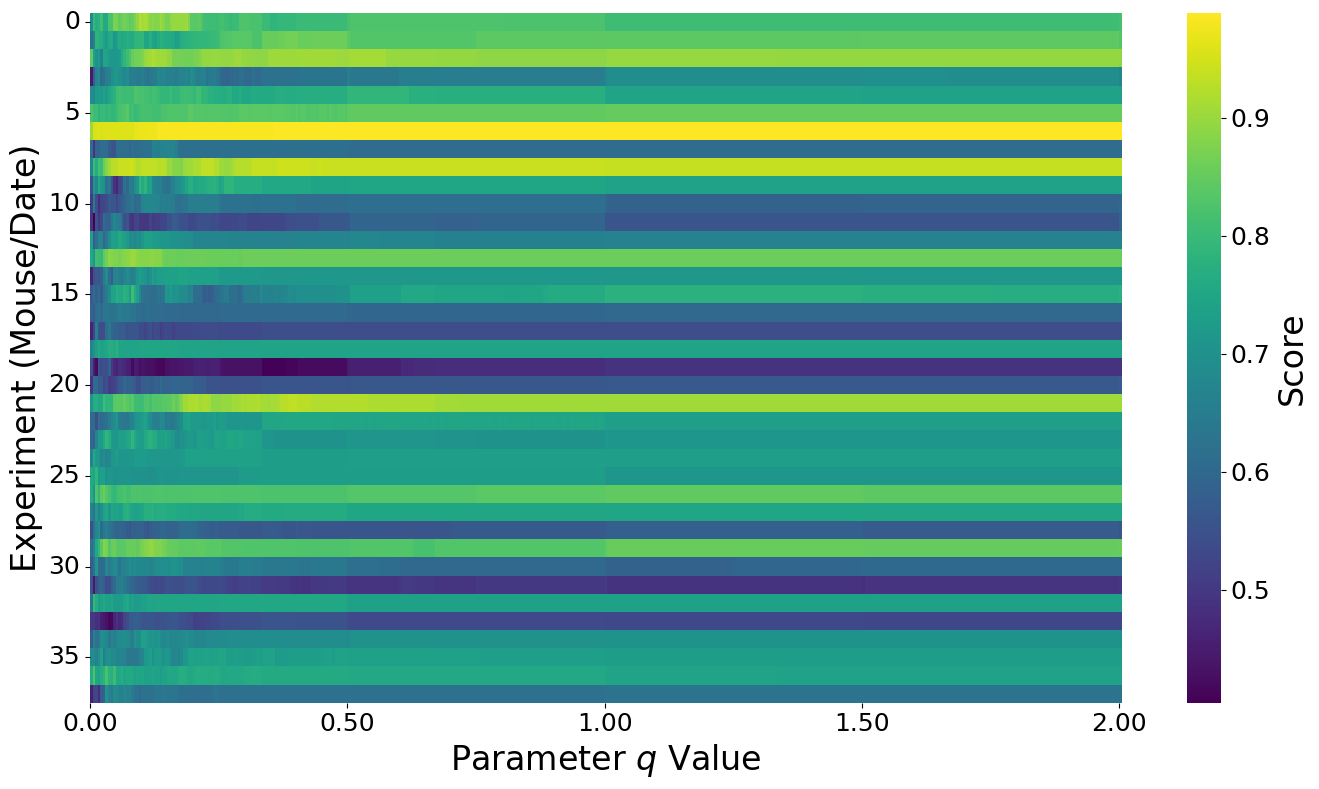

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = results_real_data.copy()

df['Experiment'] = df['Mouse'].astype(str) + "_" + df['Date'].astype(str)


heatmap_data = df.pivot(index='Experiment', columns='q', values='TDA Score')


plt.rcParams.update({
    'axes.titlesize': 24,
    'axes.labelsize': 24,
    'xtick.labelsize': 18,
    'ytick.labelsize': 18,
})


fig, ax = plt.subplots(figsize=(14, 8))


sns.heatmap(heatmap_data, 
            cmap='viridis', 
            cbar_kws={'label': 'Score'},
            ax=ax)


ax.set_ylabel("Experiment (Mouse/Date)")
ax.set_xlabel("Parameter $q$ Value")


n_cols = len(heatmap_data.columns)
x_tick_positions = np.linspace(0, n_cols - 1, 5, dtype=int)
x_tick_labels = [f"{heatmap_data.columns[i]:.2f}" for i in x_tick_positions]

ax.set_xticks(x_tick_positions)
ax.set_xticklabels(x_tick_labels, rotation=0) 


n_rows = len(heatmap_data.index)
y_tick_positions = np.arange(0, n_rows, 5) 

ax.set_yticks(y_tick_positions + 0.5) 
ax.set_yticklabels(y_tick_positions, rotation=0)

plt.tight_layout()
# plt.savefig('q_parameter_heatmap.pdf', bbox_inches='tight')
plt.show()

# Synthetic experiment 1 (5-neuron dataset)

In [ ]:
# load synthetic dataset from experiment 1

data = np.load("synthetic_raster_dataset_exp1.npz")
X = data['X']
y = data['y']

In [4]:
import pandas as pd
import numpy as np
import os
import contextlib
from tqdm.auto import tqdm
from IPython.display import display

# ------------------------------------------------------------
# q-values to test
# ------------------------------------------------------------
q_values_list = np.arange(0, 2.001, 0.005, dtype=float)

# ------------------------------------------------------------
# Output file
# ------------------------------------------------------------
csv_filename = "synthetic_exp1_q_values_results.csv"

pd.DataFrame(
    columns=["Dataset", "q", "TDA Score"]
).to_csv(csv_filename, index=False)

# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------
results_list_synthetic = []

df_display = display(
    pd.DataFrame(columns=["Dataset", "q", "TDA Score"]),
    display_id=True
)

print(f"Starting q-value sweep. Saving live to: {csv_filename}")

# ------------------------------------------------------------
# Run TDA over q-values
# ------------------------------------------------------------
for q in tqdm(q_values_list, desc="q-values"):
    
    try:
        # Suppress inner print/tqdm output from tda_rhv
        with open(os.devnull, "w") as fnull:
            with contextlib.redirect_stdout(fnull), contextlib.redirect_stderr(fnull):
                score = tda_rhv(X, y, q=q)

        # If tda_rhv returns (score, something_else), keep only score
        if isinstance(score, tuple):
            score = score[0]

        if score is not None:
            row = {
                "Dataset": "synthetic_exp1",
                "q": q,
                "TDA Score": score
            }

            results_list_synthetic.append(row)

            # Save live to CSV
            pd.DataFrame([row]).to_csv(
                csv_filename,
                mode="a",
                header=False,
                index=False
            )

            # Update display
            current_df = pd.DataFrame(results_list_synthetic)
            df_display.update(current_df.tail())

    except Exception as e:
        print(f"Error at q={q:.3f}: {e}")

# ------------------------------------------------------------
# Final dataframe
# ------------------------------------------------------------
q_results_synthetic_exp1 = pd.DataFrame(results_list_synthetic)

print("Processing complete!")
print("Final dataframe shape:", q_results_synthetic_exp1.shape)

q_results_synthetic_exp1.head()

/Users/cgty/anaconda3/envs/spike-train-tda/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Dataset,q,TDA Score
396,synthetic_exp1,1.980,0.904167
397,synthetic_exp1,1.985,0.904167
398,synthetic_exp1,1.990,0.905833
399,synthetic_exp1,1.995,0.905000
400,synthetic_exp1,2.000,0.894167


Starting q-value sweep. Saving live to: synthetic_exp1_q_values_results.csv


q-values: 100%|██████████| 401/401 [27:48<00:00,  4.16s/it]  

Processing complete!
Final dataframe shape: (401, 3)


,Dataset,q,TDA Score
0,synthetic_exp1,0.000,0.513333
1,synthetic_exp1,0.005,0.618333
2,synthetic_exp1,0.010,0.785000
3,synthetic_exp1,0.015,0.914167
4,synthetic_exp1,0.020,0.966667


# hybrid dataset

In [5]:
def generate_hybrid_dataset(n_neurons=1000, rate_percent=0.35, corr_percent=0.35, noise_percent=0.30, 
                            n_trials=30, time_bins=2000, random_state=None):
    """
    Generates a hybrid dataset of 1000 neurons mixing Rate Coding, correlation Coding, and Noise.
    
    Parameters:
    - rate_percent: Fraction of neurons dedicated to independent rate coding.
    - corr_percent: Fraction of neurons dedicated to flat-rate correlation coding.
    - noise_percent: Fraction of neurons that are pure background noise (fixed at 0.30).
    """
    
    if random_state is not None:
        np.random.seed(random_state)
    
    # 1. Validate percentages
    total_percent = rate_percent + corr_percent + noise_percent
    if not np.isclose(total_percent, 1.0):
        raise ValueError(f"Percentages must sum to 1.0. Currently sum to {total_percent}")
        
    # 2. Allocate Neurons to Pools
    n_rate = int(n_neurons * rate_percent)
    n_corr = int(n_neurons * corr_percent)
    n_noise = n_neurons - n_rate - n_corr # catches any rounding remainder
    
    # 3. Define Probabilities
    p_bg = 0.015       # Background noise
    p_corr = 0.010     # Mother signal strength
    p_baseline = 0.015 # Baseline for quiet rate-coders
    p_elevated = 0.025 # Loud rate for target rate-coders
    
    X, y = [], []
    
    for taste in [0, 1, 2]:
        for _ in range(n_trials):
            raster = np.zeros((n_neurons, time_bins), dtype=int)
            
            # ==========================================
            # POOL A: Independent Rate Coding
            # ==========================================
            if n_rate > 0:
                # Split the rate pool into 3 chunks (one for each taste)
                chunk_size = n_rate // 3
                
                for i in range(n_rate):
                    # Determine if this neuron is in the "loud" chunk for the current taste
                    if (taste == 0 and i < chunk_size) or \
                       (taste == 1 and chunk_size <= i < 2 * chunk_size) or \
                       (taste == 2 and i >= 2 * chunk_size):
                        p = p_elevated
                    else:
                        p = p_baseline
                        
                    raster[i] = np.random.binomial(1, p, time_bins)
                    
            # ==========================================
            # POOL B: Correlation Coding (Flat Rate)
            # ==========================================
            if n_corr > 0:
                corr_offset = n_rate # Starting index for Pool B
                
                # First, give all Pool B neurons their independent background noise
                for i in range(corr_offset, corr_offset + n_corr):
                    raster[i] = np.random.binomial(1, p_bg, time_bins)
                    
                # Class 0: Broad correlation (The Hub)
                if taste == 0:
                    mother = np.random.binomial(1, p_corr, time_bins)
                    # corr the first half of the pool to the mother
                    half_corr = n_corr // 2
                    for i in range(corr_offset, corr_offset + half_corr):
                        raster[i] = np.logical_or(raster[i], mother)
                    # The other half gets independent dummy trains to keep rates flat
                    for i in range(corr_offset + half_corr, corr_offset + n_corr):
                        dummy = np.random.binomial(1, p_corr, time_bins)
                        raster[i] = np.logical_or(raster[i], dummy)
                        
                # Class 1: Localized correlation (The Clusters/Pairs)
                elif taste == 1:
                    cluster_size = 5 # Small groups of neurons firing together
                    for i in range(corr_offset, corr_offset + n_corr, cluster_size):
                        mother = np.random.binomial(1, p_corr, time_bins)
                        # Apply this local mother train to the small cluster
                        for j in range(i, min(i + cluster_size, corr_offset + n_corr)):
                            raster[j] = np.logical_or(raster[j], mother)
                            
                # Class 2: No correlation (Independent Flat Rate)
                elif taste == 2:
                    for i in range(corr_offset, corr_offset + n_corr):
                        dummy = np.random.binomial(1, p_corr, time_bins)
                        raster[i] = np.logical_or(raster[i], dummy)

            # ==========================================
            # POOL C: Pure Background Noise
            # ==========================================
            if n_noise > 0:
                noise_offset = n_rate + n_corr
                for i in range(noise_offset, n_neurons):
                    # Fixed at p_elevated volume to act as dense background clutter
                    raster[i] = np.random.binomial(1, p_elevated, time_bins)
                    
            X.append(raster)
            y.append(taste)
            
    return X, np.array(y)

In [ ]:
import pandas as pd
import numpy as np
import os
import contextlib
from multiprocess import Pool
from tqdm.auto import tqdm
from IPython.display import display

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------
X, y = generate_hybrid_dataset(n_neurons=100)

# ------------------------------------------------------------
# q-values to test
# ------------------------------------------------------------
q_values_list = np.arange(0, 2.001, 0.005, dtype=float)

# ------------------------------------------------------------
# Output file
# ------------------------------------------------------------
csv_filename = "synthetic_hybrid_coding_q_values_results.csv"

# ------------------------------------------------------------
# Resume logic: do not overwrite already-computed q-values
# ------------------------------------------------------------
if os.path.exists(csv_filename):
    existing_df = pd.read_csv(csv_filename)

    if len(existing_df) > 0:
        completed_qs = set(np.round(existing_df["q"].astype(float), 6))
    else:
        completed_qs = set()
else:
    existing_df = pd.DataFrame(columns=["Dataset", "q", "TDA Score"])
    existing_df.to_csv(csv_filename, index=False)
    completed_qs = set()

remaining_q_values = [
    q for q in q_values_list
    if round(float(q), 6) not in completed_qs
]

print(f"Existing completed q-values: {len(completed_qs)}")
print(f"Remaining q-values to compute: {len(remaining_q_values)}")

if len(remaining_q_values) > 0:
    print(f"Starting from q = {remaining_q_values[0]:.3f}")
else:
    print("All q-values already computed.")

# ------------------------------------------------------------
# Worker function
# ------------------------------------------------------------
def process_single_q(q):
    """
    Worker function for one q-value.

    Uses global X and y.
    """
    try:
        with open(os.devnull, "w") as fnull:
            with contextlib.redirect_stdout(fnull), contextlib.redirect_stderr(fnull):
                score = tda_rhv(X, y, q=q)

        if isinstance(score, tuple):
            score = score[0]

        if score is None:
            return None

        return {
            "Dataset": "synthetic_hybrid_coding",
            "q": float(q),
            "TDA Score": float(score)
        }

    except Exception as e:
        return {
            "error": str(e),
            "q": float(q)
        }


# ------------------------------------------------------------
# Parallel q-value sweep
# ------------------------------------------------------------
if __name__ == "__main__":

    n_cpus = os.cpu_count()
    print(f"Using {n_cpus} CPUs.")
    print(f"Saving live to: {csv_filename}")

    results_list_h1 = existing_df.to_dict("records")

    df_display = display(
        existing_df.tail(),
        display_id=True
    )

    if len(remaining_q_values) > 0:

        with Pool(processes=n_cpus) as pool:

            for res in tqdm(
                pool.imap_unordered(process_single_q, remaining_q_values),
                total=len(remaining_q_values),
                desc="q-values"
            ):

                if res is None:
                    continue

                if isinstance(res, dict) and "error" in res:
                    print(f"Error at q={res['q']:.3f}: {res['error']}")
                    continue

                # Append to memory
                results_list_h1.append(res)

                # Append to CSV without rewriting old rows
                pd.DataFrame([res]).to_csv(
                    csv_filename,
                    mode="a",
                    header=False,
                    index=False
                )

                # Update live display
                current_df = pd.DataFrame(results_list_h1)
                df_display.update(current_df.tail())

    # ------------------------------------------------------------
    # Final dataframe
    # ------------------------------------------------------------
    q_results_h1_dataset = pd.read_csv(csv_filename)
    q_results_h1_dataset = (
        q_results_h1_dataset
        .sort_values(by="q")
        .reset_index(drop=True)
    )

    print("Processing complete!")
    print("Final dataframe shape:", q_results_h1_dataset.shape)

    display(q_results_h1_dataset.head())
    display(q_results_h1_dataset.tail())

Existing completed q-values: 21
Remaining q-values to compute: 380
Starting from q = 0.105
Using 8 CPUs.
Saving live to: synthetic_hybrid_coding_q_values_results.csv


,Dataset,q,TDA Score
396,synthetic_hybrid_coding,1.980,0.812963
397,synthetic_hybrid_coding,1.985,0.824074
398,synthetic_hybrid_coding,1.990,0.833333
399,synthetic_hybrid_coding,1.995,0.824074
400,synthetic_hybrid_coding,2.000,0.788889


q-values: 100%|██████████| 380/380 [26:57:09<00:00, 255.34s/it]     

Processing complete!
Final dataframe shape: (401, 3)


,Dataset,q,TDA Score
0,synthetic_hybrid_coding,0.000,0.333333
1,synthetic_hybrid_coding,0.005,0.459259
2,synthetic_hybrid_coding,0.010,0.601852
3,synthetic_hybrid_coding,0.015,0.657407
4,synthetic_hybrid_coding,0.020,0.662963


,Dataset,q,TDA Score
396,synthetic_hybrid_coding,1.980,0.812963
397,synthetic_hybrid_coding,1.985,0.824074
398,synthetic_hybrid_coding,1.990,0.833333
399,synthetic_hybrid_coding,1.995,0.824074
400,synthetic_hybrid_coding,2.000,0.788889


# h1 dataset

In [5]:
data = np.load("h1_dataset.npz")
X = data['X']
y = data['y']


In [7]:
import pandas as pd
import numpy as np
import os
import contextlib
from multiprocess import Pool
from tqdm.auto import tqdm
from IPython.display import display
import persim



# ------------------------------------------------------------
# q-values to test
# ------------------------------------------------------------
q_values_list = np.arange(0, 2.001, 0.005, dtype=float)

# ------------------------------------------------------------
# Output file
# ------------------------------------------------------------
csv_filename = "h1_dataset_q_values_results.csv"

# ------------------------------------------------------------
# Resume logic: do not overwrite already-computed q-values
# ------------------------------------------------------------
if os.path.exists(csv_filename):
    existing_df = pd.read_csv(csv_filename)

    if len(existing_df) > 0:
        completed_qs = set(np.round(existing_df["q"].astype(float), 6))
    else:
        completed_qs = set()
else:
    existing_df = pd.DataFrame(columns=["Dataset", "q", "TDA Score"])
    existing_df.to_csv(csv_filename, index=False)
    completed_qs = set()

remaining_q_values = [
    q for q in q_values_list
    if round(float(q), 6) not in completed_qs
]

print(f"Existing completed q-values: {len(completed_qs)}")
print(f"Remaining q-values to compute: {len(remaining_q_values)}")

if len(remaining_q_values) > 0:
    print(f"Starting from q = {remaining_q_values[0]:.3f}")
else:
    print("All q-values already computed.")

# ------------------------------------------------------------
# Worker function
# ------------------------------------------------------------
def process_single_q(q):
    """
    Worker function for one q-value.

    Uses global X and y.
    """
    try:
        with open(os.devnull, "w") as fnull:
            with contextlib.redirect_stdout(fnull), contextlib.redirect_stderr(fnull):
                score = tda_rhv(X, y,dim = 1, q=q) # we classify by H1 in this dataset

        if isinstance(score, tuple):
            score = score[0]

        if score is None:
            return None

        return {
            "Dataset": "h1_dataset",
            "q": float(q),
            "TDA Score": float(score)
        }

    except Exception as e:
        return {
            "error": str(e),
            "q": float(q)
        }


# ------------------------------------------------------------
# Parallel q-value sweep
# ------------------------------------------------------------
if __name__ == "__main__":

    n_cpus = os.cpu_count()
    print(f"Using {n_cpus} CPUs.")
    print(f"Saving live to: {csv_filename}")

    results_list_h1 = existing_df.to_dict("records")

    df_display = display(
        existing_df.tail(),
        display_id=True
    )

    if len(remaining_q_values) > 0:

        with Pool(processes=n_cpus) as pool:

            for res in tqdm(
                pool.imap_unordered(process_single_q, remaining_q_values),
                total=len(remaining_q_values),
                desc="q-values"
            ):

                if res is None:
                    continue

                if isinstance(res, dict) and "error" in res:
                    print(f"Error at q={res['q']:.3f}: {res['error']}")
                    continue

                # Append to memory
                results_list_h1.append(res)

                # Append to CSV without rewriting old rows
                pd.DataFrame([res]).to_csv(
                    csv_filename,
                    mode="a",
                    header=False,
                    index=False
                )

                # Update live display
                current_df = pd.DataFrame(results_list_h1)
                df_display.update(current_df.tail())

    # ------------------------------------------------------------
    # Final dataframe
    # ------------------------------------------------------------
    q_results_synthetic_hybrid_coding = pd.read_csv(csv_filename)
    q_results_synthetic_hybrid_coding = (
        q_results_synthetic_hybrid_coding
        .sort_values(by="q")
        .reset_index(drop=True)
    )

    print("Processing complete!")
    print("Final dataframe shape:", q_results_synthetic_hybrid_coding.shape)

    display(q_results_synthetic_hybrid_coding.head())
    display(q_results_synthetic_hybrid_coding.tail())

Existing completed q-values: 0
Remaining q-values to compute: 401
Starting from q = 0.000
Using 8 CPUs.
Saving live to: h1_dataset_q_values_results.csv


,Dataset,q,TDA Score
396,h1_dataset,1.980,0.952778
397,h1_dataset,1.985,0.952778
398,h1_dataset,1.990,0.952778
399,h1_dataset,1.995,0.952778
400,h1_dataset,2.000,0.961111


q-values: 100%|██████████| 401/401 [08:53<00:00,  1.33s/it]

Processing complete!
Final dataframe shape: (401, 3)


,Dataset,q,TDA Score
0,h1_dataset,0.000,0.500000
1,h1_dataset,0.005,0.836111
2,h1_dataset,0.010,0.680556
3,h1_dataset,0.015,0.991667
4,h1_dataset,0.020,1.000000


,Dataset,q,TDA Score
396,h1_dataset,1.980,0.952778
397,h1_dataset,1.985,0.952778
398,h1_dataset,1.990,0.952778
399,h1_dataset,1.995,0.952778
400,h1_dataset,2.000,0.961111


# plot all together

In [8]:
# load all four
results_real_data = pd.read_csv('q_values_results.csv', dtype={'Mouse': str, 'Date': str, 'q': float, 'TDA Score': float})
results_five_neuron_data = pd.read_csv('synthetic_exp1_q_values_results.csv', dtype={'Dataset': str, 'q': float, 'TDA Score': float})
results_hybrid_data = pd.read_csv('synthetic_hybrid_coding_q_values_results.csv', dtype={'Dataset': str, 'q': float, 'TDA Score': float})
results_h1_data = pd.read_csv('h1_dataset_q_values_results.csv', dtype={'Dataset': str, 'q': float, 'TDA Score': float})




In [31]:
results_real_data.head()

,Mouse,Date,q,TDA Score
0,CB279,122021,0.000,0.822222
1,CB279,122021,0.005,0.808333
2,CB279,122021,0.010,0.802778
3,CB279,122021,0.015,0.783333
4,CB279,122021,0.020,0.797222


In [32]:
results_five_neuron_data.head()

,Dataset,q,TDA Score
0,synthetic_exp1,0.000,0.513333
1,synthetic_exp1,0.005,0.618333
2,synthetic_exp1,0.010,0.785000
3,synthetic_exp1,0.015,0.914167
4,synthetic_exp1,0.020,0.966667


In [33]:
results_hybrid_data.head()

,Dataset,q,TDA Score
0,synthetic_hybrid_coding,0.000,0.333333
1,synthetic_hybrid_coding,0.005,0.459259
2,synthetic_hybrid_coding,0.010,0.601852
3,synthetic_hybrid_coding,0.015,0.657407
4,synthetic_hybrid_coding,0.020,0.662963


In [35]:
results_h1_data.head()

,Dataset,q,TDA Score
0,h1_dataset,0.000,0.500000
1,h1_dataset,0.030,1.000000
2,h1_dataset,0.035,1.000000
3,h1_dataset,0.020,1.000000
4,h1_dataset,0.015,0.991667


In [36]:
results_h1_data_sorted = results_h1_data.copy()

# Round q values to avoid floating-point issues like 0.03000000004
results_h1_data_sorted["q"] = results_h1_data_sorted["q"].round(3)

# Keep only rows with q between 0 and 2
results_h1_data_sorted = results_h1_data_sorted[
    (results_h1_data_sorted["q"] >= 0) &
    (results_h1_data_sorted["q"] <= 2)
]

# If there is exactly one TDA Score per q, this just sorts them
# If there are duplicate q values, this averages their TDA Scores
results_h1_data_sorted = (
    results_h1_data_sorted
    .groupby(["Dataset", "q"], as_index=False)["TDA Score"]
    .mean()
    .sort_values("q")
    .reset_index(drop=True)
)

results_h1_data_sorted.head()

,Dataset,q,TDA Score
0,h1_dataset,0.000,0.500000
1,h1_dataset,0.005,0.836111
2,h1_dataset,0.010,0.680556
3,h1_dataset,0.015,0.991667
4,h1_dataset,0.020,1.000000


In [37]:
results_h1_data = results_h1_data_sorted.copy()
results_h1_data.head()

,Dataset,q,TDA Score
0,h1_dataset,0.000,0.500000
1,h1_dataset,0.005,0.836111
2,h1_dataset,0.010,0.680556
3,h1_dataset,0.015,0.991667
4,h1_dataset,0.020,1.000000


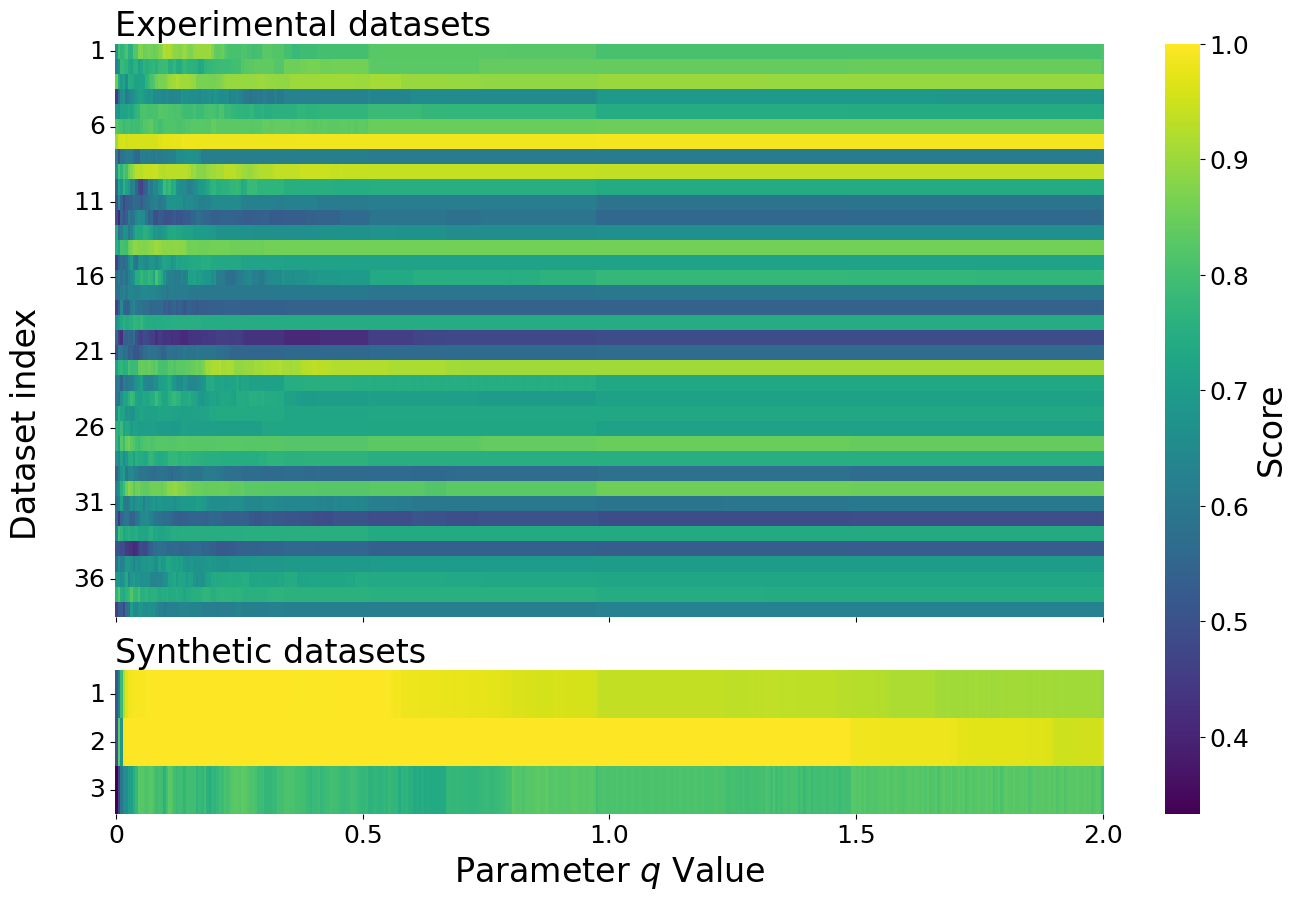

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------------------------
# Real data
# ---------------------------------------------------------
real_df = results_real_data.copy()
real_df['Experiment'] = real_df['Mouse'].astype(str) + "_" + real_df['Date'].astype(str)

heatmap_real = real_df.pivot(
    index='Experiment',
    columns='q',
    values='TDA Score'
)

# ---------------------------------------------------------
# Synthetic data
# ---------------------------------------------------------
heatmap_five = results_five_neuron_data.pivot(
    index='Dataset',
    columns='q',
    values='TDA Score'
)

heatmap_hybrid = results_hybrid_data.pivot(
    index='Dataset',
    columns='q',
    values='TDA Score'
)

heatmap_h1 = results_h1_data.pivot(
    index='Dataset',
    columns='q',
    values='TDA Score'
)

# ---------------------------------------------------------
# Force all heatmaps to use the same q-values / same columns
# ---------------------------------------------------------
common_qs = sorted(
    set(heatmap_real.columns)
    & set(heatmap_five.columns)
    & set(heatmap_hybrid.columns)
    & set(heatmap_h1.columns)
)

heatmap_real = heatmap_real[common_qs]
heatmap_five = heatmap_five[common_qs]
heatmap_hybrid = heatmap_hybrid[common_qs]
heatmap_h1 = heatmap_h1[common_qs]

# Stack the 3 synthetic datasets into one 3-row heatmap
heatmap_synth = pd.concat(
    [heatmap_five, heatmap_h1, heatmap_hybrid],
    axis=0
)

# Label synthetic rows as 1, 2, 3
heatmap_synth.index = [1, 2, 3]

# ---------------------------------------------------------
# Shared color scale
# ---------------------------------------------------------
all_values = np.concatenate([
    heatmap_real.to_numpy().ravel(),
    heatmap_synth.to_numpy().ravel()
])

vmin = np.nanmin(all_values)
vmax = np.nanmax(all_values)

# If you want fixed classification scale instead, use:
# vmin, vmax = 0.0, 1.0

# ---------------------------------------------------------
# Plot settings
# ---------------------------------------------------------
plt.rcParams.update({
    'axes.titlesize': 24,
    'axes.labelsize': 24,
    'xtick.labelsize': 18,
    'ytick.labelsize': 18,
})

fig = plt.figure(figsize=(14, 10))
fig.supylabel("Dataset index", fontsize=24,x= 0.05)
# 2 rows, 2 columns: left for heatmaps, right for one shared colorbar
gs = fig.add_gridspec(
    nrows=2,
    ncols=2,
    width_ratios=[40, 1.4],
    height_ratios=[8, 2],
    hspace=0.15,
    wspace=0.12
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)
cbar_ax = fig.add_subplot(gs[:, 1])

# ---------------------------------------------------------
# Top heatmap: experimental data
# ---------------------------------------------------------
hm1 = sns.heatmap(
    heatmap_real,
    cmap='viridis',
    vmin=vmin,
    vmax=vmax,
    cbar=True,
    cbar_ax=cbar_ax,
    cbar_kws={'label': 'Score'},
    ax=ax1,
    xticklabels= False
)

ax1.set_title("Experimental datasets", loc='left')
ax1.set_ylabel("")
ax1.set_xlabel("")



# y-ticks every 5 rows
n_rows_real = len(heatmap_real.index)
y_tick_positions_real = np.arange(0, n_rows_real, 5)
ax1.set_yticks(y_tick_positions_real + 0.5)
ax1.set_yticklabels(
    [str(i) for i in range(1, n_rows_real + 1, 5)],
    rotation=0
)

# ---------------------------------------------------------
# Bottom heatmap: synthetic datasets
# ---------------------------------------------------------
sns.heatmap(
    heatmap_synth,
    cmap='viridis',
    vmin=vmin,
    vmax=vmax,
    cbar=False,
    ax=ax2,
    xticklabels= False
)

ax2.set_title("Synthetic datasets", loc='left')
# ax2.set_ylabel("")
ax2.set_xlabel("Parameter $q$ Value")

# same x ticks, same scale
# ax2.set_xticks(x_tick_positions + 0.5)
# ax2.set_xticklabels(x_tick_labels, rotation=0)

# x-ticks
# n_cols = len(heatmap_real.columns)
# x_tick_positions = np.linspace(0, n_cols - 1, 5, dtype=int)
# x_tick_labels = [f"{heatmap_real.columns[i]:.2f}" for i in x_tick_positions]
#############
# ---------------------------------------------------------
# X-axis ticks
# ---------------------------------------------------------
desired_qs = [0.0, 0.5, 1.0, 1.5, 2.0]

n_cols = heatmap_real.shape[1]

x_tick_positions = [(q / 2.0) * (n_cols - 1) + 0.5 for q in desired_qs]
x_tick_labels = ["0", "0.5", "1.0", "1.5", "2.0"]

# top panel: ticks aligned, labels hidden
ax1.set_xticks(x_tick_positions)
ax1.tick_params(axis='x', labelbottom=False)

# bottom panel: ticks and labels shown
ax2.set_xticks(x_tick_positions)
ax2.set_xticklabels(x_tick_labels, rotation=0)

# force both heatmaps to use identical x-limits
ax1.set_xlim(0, n_cols)
ax2.set_xlim(0, n_cols)

#############

# y-ticks for synthetic datasets
n_rows_synth = len(heatmap_synth.index)
y_tick_positions_synth = np.arange(0, n_rows_synth)
ax2.set_yticks(y_tick_positions_synth + 0.5)
ax2.set_yticklabels([1, 2, 3], rotation=0)

# ---------------------------------------------------------
# Optional: make sure x-limits are identical
# ---------------------------------------------------------
ax2.set_xlim(ax1.get_xlim())

# ---------------------------------------------------------
# Final layout
# ---------------------------------------------------------
cbar_ax.tick_params(labelsize=18)
cbar_ax.set_ylabel("Score", fontsize=24)

plt.savefig('q_parameter_heatmap_combined.pdf', bbox_inches='tight')

plt.show()